# Player-vs-player matrices for NMF

The aim is to factorise a **player × player matrix** with NMF
(non-negative matrix factorisation). This notebook builds two matrices for
the same 100 players and checks how much of each is filled in:

- **Players**: the 100 players with the most ATP tour-level matches in
  2024, i.e. the busiest players going into 2025.
- **Matrix 1, meetings**: how many times each pair played each other in
  2025 (calendar year).
- **Matrix 2, performance against Elo**: for each 2025 match, the row
  player's result (1 for a win, 0 for a loss) minus the Elo win
  probability they had before the match. Positive means they did better
  than expected against that opponent. Pairs that met more than once get
  the average of their per-match residuals; pairs that never met are left
  empty (null). A **confidence-adjusted** version then shrinks each cell
  towards 0 according to how many matches it rests on.

Data: the match-by-match Elo predictions saved by `elo_prediction.ipynb`
(`data/elo_predictions.csv`), so **run that notebook first**. Each match's
probability uses the ratings just before it and the settings tuned for that
year, and player names are already merged across spellings.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

path = os.path.join("data", "elo_predictions.csv")
if not os.path.exists(path):
    raise FileNotFoundError("Run elo_prediction.ipynb first: it writes "
                            "data/elo_predictions.csv")
matches = pd.read_csv(path, parse_dates=["Date"])
print(matches.groupby("Year").size().tail(4).to_string())

Year
2023    2685
2024    2709
2025    2594
2026    2345


Matches are assigned to years by their date (the 2025 season file starts on
29 December 2024). Walkovers and other matches that weren't played are
already left out; retirements count as played.

## 1. The 100 busiest players of 2024

In [2]:
in_2024 = matches[matches["Year"] == 2024]
played_2024 = pd.concat([in_2024["Winner"], in_2024["Loser"]]).value_counts()
top = played_2024.head(100)
players = list(top.index)
print(f"{len(played_2024)} players played in 2024; the top 100 played "
      f"{top.min()}-{top.max()} matches (median {top.median():.0f})")
print(f"Players on exactly {top.min()} matches: "
      f"{(played_2024 == top.min()).sum()} in total, "
      f"{(top == top.min()).sum()} of them included")
top.head(10)

291 players played in 2024; the top 100 played 20-79 matches (median 44)
Players on exactly 20 matches: 2 in total, 2 of them included


Zverev A.       79
Sinner J.       76
Rune H.         69
Rublev A.       68
Fritz T.        67
Ruud C.         65
Dimitrov G.     64
Shelton B.      64
Medvedev D.     62
De Minaur A.    62
Name: count, dtype: int64

## 2. Matrix 1: meetings between each pair in 2025

In [3]:
in_2025 = matches[(matches["Year"] == 2025)
                  & matches["Winner"].isin(players)
                  & matches["Loser"].isin(players)]
index = {p: i for i, p in enumerate(players)}
matrix = np.zeros((len(players), len(players)), dtype=int)
for w, l in zip(in_2025["Winner"], in_2025["Loser"]):
    matrix[index[w], index[l]] += 1
    matrix[index[l], index[w]] += 1
matrix = pd.DataFrame(matrix, index=players, columns=players)

all_2025 = matches[matches["Year"] == 2025]
involved = all_2025["Winner"].isin(players) | all_2025["Loser"].isin(players)
print(f"2025 matches: {len(all_2025):,} in total, {involved.sum():,} involving "
      f"at least one of the 100, {len(in_2025):,} between two of them")
matrix.iloc[:8, :8]

2025 matches: 2,594 in total, 2,348 involving at least one of the 100, 1,322 between two of them


,Zverev A.,Sinner J.,Rune H.,Rublev A.,Fritz T.,Ruud C.,Dimitrov G.,Shelton B.
Zverev A.,0,4,0,0,1,0,0,4
Sinner J.,4,0,1,1,0,1,1,4
Rune H.,0,1,0,0,0,1,0,0
Rublev A.,0,1,0,0,1,0,0,1
Fritz T.,1,0,0,1,0,1,0,1
Ruud C.,0,1,1,0,1,0,0,0
Dimitrov G.,0,1,0,0,0,0,0,0
Shelton B.,4,4,0,1,1,0,0,0


## 3. How much of matrix 1 is filled in

The matrix has 100 × 100 = 10,000 cells. The 100 diagonal cells can never
be filled, and every pair appears twice (row A column B, and row B column
A), so the real question is how many of the **4,950 distinct pairs** played
each other at least once.

In [4]:
n = len(players)
pairs = n * (n - 1) // 2
upper = matrix.to_numpy()[np.triu_indices(n, k=1)]
filled = (upper > 0).sum()
print(f"Distinct pairs:             {pairs:,}")
print(f"Pairs that played in 2025:  {filled:,} ({filled / pairs:.1%})")
print(f"Pairs that didn't:          {pairs - filled:,} "
      f"({1 - filled / pairs:.1%})")
print(f"Of all 10,000 cells:        {(matrix.to_numpy() > 0).sum():,} filled "
      f"({(matrix.to_numpy() > 0).mean():.1%})")
print("\nMatches per filled pair:")
print(pd.Series(upper[upper > 0]).value_counts().sort_index()
      .rename_axis("matches").to_frame("pairs").T.to_string())

Distinct pairs:             4,950
Pairs that played in 2025:  1,065 (21.5%)
Pairs that didn't:          3,885 (78.5%)
Of all 10,000 cells:        2,130 filled (21.3%)

Matches per filled pair:
matches    1    2   3  4  6
pairs    867  151  37  9  1


In [5]:
opponents = (matrix > 0).sum(axis=1)
played_2025 = matrix.sum(axis=1)
summary = pd.DataFrame({"matches_2024": top,
                        "matches_v_top100_2025": played_2025,
                        "distinct_top100_opponents": opponents})
print(f"Distinct top-100 opponents per player in 2025: "
      f"median {opponents.median():.0f}, range "
      f"{opponents.min()}-{opponents.max()}")
print(f"Players with no 2025 match against the others: "
      f"{(played_2025 == 0).sum()}")
summary.sort_values("distinct_top100_opponents").head(8)

Distinct top-100 opponents per player in 2025: median 22, range 0-41
Players with no 2025 match against the others: 3


,matches_2024,matches_v_top100_2025,distinct_top100_opponents
Kotov P.,40,0,0
Purcell M.,34,0,0
Van Assche L.,23,0,0
Monteiro T.,20,1,1
Coric B.,29,2,2
Coria F.,23,2,2
Koepfer D.,31,2,2
Ruusuvuori E.,28,2,2


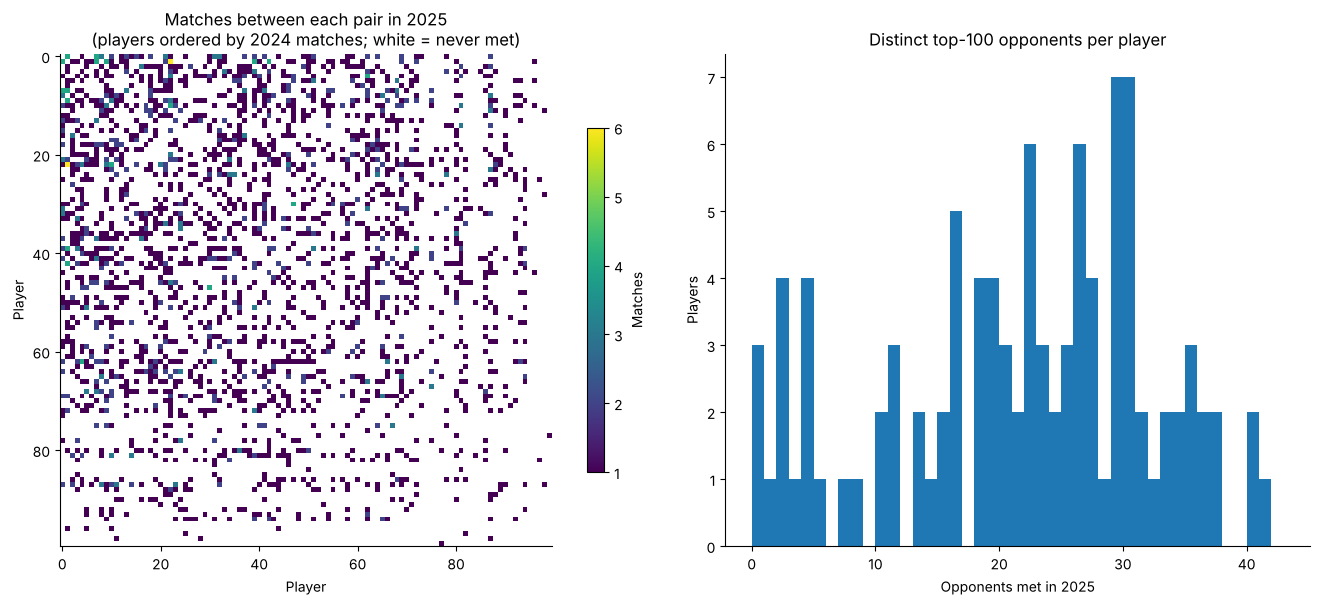

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios": [1.2, 1]})
im = axes[0].imshow(np.where(matrix > 0, matrix, np.nan), cmap="viridis",
                    interpolation="nearest")
axes[0].set_title("Matches between each pair in 2025\n"
                  "(players ordered by 2024 matches; white = never met)")
axes[0].set_xlabel("Player")
axes[0].set_ylabel("Player")
fig.colorbar(im, ax=axes[0], shrink=0.7, label="Matches")
axes[1].hist(opponents, bins=range(0, opponents.max() + 3))
axes[1].set_title("Distinct top-100 opponents per player")
axes[1].set_xlabel("Opponents met in 2025")
axes[1].set_ylabel("Players")
plt.tight_layout()

## 4. Matrix 2: performance against Elo

For every 2025 match between two of the 100, the row player's **residual**
is their result minus their Elo win probability before the match:

- a player given a 30% chance who wins scores **+0.70**; if they lose,
  **-0.30**;
- the opponent's residual is the exact opposite, so the matrix is
  antisymmetric: cell (A, B) = -cell (B, A).

**Retirements are left out**: a match where one player retires injured
isn't a fair measure of how either played. Each cell is the average
residual over that pair's completed 2025 matches, and pairs with no
completed match are null. So it is filled in where matrix 1 is non-zero,
except for pairs whose only meetings ended in a retirement.

In [7]:
pair_matches = matches[(matches["Year"] == 2025)
                       & matches["Winner"].isin(players)
                       & matches["Loser"].isin(players)
                       & ~matches["retired"]]
retired = (matches["Year"] == 2025) & matches["retired"] \
    & matches["Winner"].isin(players) & matches["Loser"].isin(players)
print(f"{len(pair_matches):,} completed matches between two of the 100; "
      f"{retired.sum()} retirements left out")
rows = []
for w, l, p in zip(pair_matches["Winner"], pair_matches["Loser"],
                   pair_matches["elo_p"]):
    rows.append((w, l, 1 - p))   # winner: 1 - their win probability
    rows.append((l, w, 0 - (1 - p)))  # loser: 0 - their win probability
residuals = pd.DataFrame(rows, columns=["player", "opponent", "residual"])
average = residuals.groupby(["player", "opponent"])["residual"].mean()
residual_matrix = (average.unstack()
                   .reindex(index=players, columns=players))

values = residual_matrix.to_numpy()
filled = np.isfinite(values)
print(f"Cells with a value: {filled.sum():,} of {values.size:,} "
      f"({filled.mean():.1%}); pairs: {filled.sum() // 2:,} of 4,950")
lost = (matrix.to_numpy() > 0) & ~filled
print(f"Pairs that met but only in a retirement (now null): "
      f"{lost.sum() // 2}")
print(f"Antisymmetric: {np.allclose(values[filled], -values.T[filled])}")
print(f"Residuals range from {np.nanmin(values):+.2f} to "
      f"{np.nanmax(values):+.2f}; mean of filled cells "
      f"{np.nanmean(values):+.3f}")
residual_matrix.iloc[:8, :8].round(2)

1,265 completed matches between two of the 100; 57 retirements left out
Cells with a value: 2,058 of 10,000 (20.6%); pairs: 1,029 of 4,950
Pairs that met but only in a retirement (now null): 36
Antisymmetric: True
Residuals range from -0.93 to +0.93; mean of filled cells -0.000


opponent,Zverev A.,Sinner J.,Rune H.,Rublev A.,Fritz T.,Ruud C.,Dimitrov G.,Shelton B.
player,,,,,,,,
Zverev A.,NaN,-0.19,NaN,NaN,-0.61,NaN,NaN,0.33
Sinner J.,0.19,NaN,0.07,0.06,NaN,0.20,NaN,0.09
Rune H.,NaN,-0.07,NaN,NaN,NaN,0.52,NaN,NaN
Rublev A.,NaN,-0.06,NaN,NaN,-0.31,NaN,NaN,-0.37
Fritz T.,0.61,NaN,NaN,0.31,NaN,-0.57,NaN,-0.63
Ruud C.,NaN,-0.20,-0.52,NaN,0.57,NaN,NaN,NaN
Dimitrov G.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shelton B.,-0.33,-0.09,NaN,0.37,0.63,NaN,NaN,NaN


Who did better or worse than their Elo expected against the other 99 in
2025: each player's average residual per match, and how many of those
matches they played. With so few matches per player these are noisy: one
upset moves a player's average a lot.

In [8]:
per_player = residuals.groupby("player")["residual"].agg(["mean", "size"])
per_player.columns = ["average_residual", "matches"]
per_player = per_player.reindex(players)
print("Best against expectation (10+ matches):")
print(per_player[per_player["matches"] >= 10]
      .sort_values("average_residual", ascending=False).head(8)
      .round(3).to_string(), "\n")
print("Worst against expectation (10+ matches):")
print(per_player[per_player["matches"] >= 10]
      .sort_values("average_residual").head(8).round(3).to_string())

Best against expectation (10+ matches):
                      average_residual  matches
player                                         
Evans D.                         0.224     11.0
Munar J.                         0.186     35.0
Bublik A.                        0.176     45.0
Rinderknech A.                   0.145     35.0
Duckworth J.                     0.141     12.0
Dimitrov G.                      0.134     16.0
Davidovich Fokina A.             0.118     49.0
Altmaier D.                      0.115     29.0 

Worst against expectation (10+ matches):
              average_residual  matches
player                                 
Gaston H.               -0.286     14.0
Lajovic D.              -0.225     10.0
Wawrinka S.             -0.223     13.0
Baez S.                 -0.189     20.0
Safiullin R.            -0.154     18.0
Korda S.                -0.138     28.0
Jarry N.                -0.123     17.0
Khachanov K.            -0.122     34.0


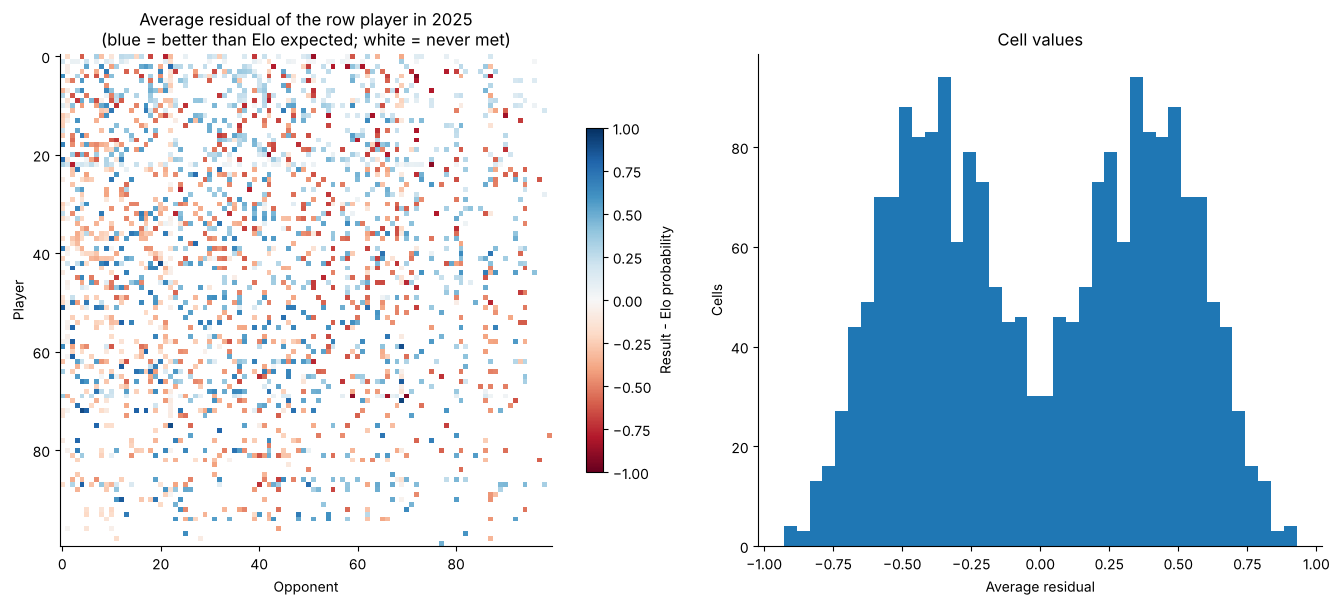

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios": [1.2, 1]})
im = axes[0].imshow(residual_matrix, cmap="RdBu", vmin=-1, vmax=1,
                    interpolation="nearest")
axes[0].set_title("Average residual of the row player in 2025\n"
                  "(blue = better than Elo expected; white = never met)")
axes[0].set_xlabel("Opponent")
axes[0].set_ylabel("Player")
fig.colorbar(im, ax=axes[0], shrink=0.7, label="Result - Elo probability")
axes[1].hist(values[filled], bins=40)
axes[1].set_title("Cell values")
axes[1].set_xlabel("Average residual")
axes[1].set_ylabel("Cells")
plt.tight_layout()

## 5. Adjusting the residuals for confidence

A single upset says much less than a pair where one player beats Elo's
expectations meeting after meeting. Most of the variation between cells is
just match-to-match luck, so each cell is shrunk towards 0 by how little
evidence it rests on (an empirical-Bayes adjustment):

$$\text{adjusted} = \text{average residual} \times
\frac{\tau^2}{\tau^2 + \sigma^2 / n}$$

- $n$ is the number of matches the pair played;
- $\sigma^2$ is the luck in one match: a result of 1 or 0 against a win
  probability $p$ varies by $p(1-p)$ (0.25 for an even match, less for a
  mismatch). It is averaged over **all** the matches, so every match counts
  as equally informative and a cell's confidence depends only on how many
  times the pair met. (Using each match's own $p(1-p)$ would treat an upset
  of a heavy favourite as very strong evidence, but those upsets are often
  injuries, and the Elo is a little overconfident at the
  extremes.)
- $\tau^2$ is how much **real** head-to-head over- or under-performance
  varies between pairs. It is estimated from the data: the variance of the
  cell averages, minus the part luck alone would produce.

With little evidence ($\sigma^2 / n$ large) a cell is pulled almost to 0;
the more matches agree, the more of the average is kept. The matrix stays
antisymmetric and null where pairs never met.

In [10]:
match_luck = (pair_matches["elo_p"] * (1 - pair_matches["elo_p"])).mean()
cells = residuals.groupby(["player", "opponent"])["residual"] \
    .agg(["mean", "size"]).rename(columns={"size": "n"})
cells["luck_variance"] = match_luck / cells["n"]
print(f"Luck in one match (average p(1-p)): {match_luck:.3f}")

tau2 = max(cells["mean"].var() - cells["luck_variance"].mean(), 1e-6)
cells["weight"] = tau2 / (tau2 + cells["luck_variance"])
cells["adjusted"] = cells["mean"] * cells["weight"]
print(f"Variance of the cell averages:      {cells['mean'].var():.4f}")
print(f"  of which luck alone would give:    "
      f"{cells['luck_variance'].mean():.4f}")
print(f"  real head-to-head variation (tau2): {tau2:.4f} "
      f"(about +/-{np.sqrt(tau2):.2f} per match)")
print(f"Equivalent to shrinking every pair towards 0 with about "
      f"{match_luck / tau2:.0f} matches of prior evidence\n")
print("Share of the average kept, by number of meetings:")
print(cells.groupby("n")["weight"].mean().round(3).to_frame("kept").T
      .to_string())

adjusted_matrix = (cells["adjusted"].unstack()
                   .reindex(index=players, columns=players))
adjusted = adjusted_matrix.to_numpy()
print(f"\nStill antisymmetric: "
      f"{np.allclose(adjusted[filled], -adjusted.T[filled])}; "
      f"same null cells as the raw residuals: "
      f"{(np.isfinite(adjusted) == filled).all()}")

Luck in one match (average p(1-p)): 0.206
Variance of the cell averages:      0.1918
  of which luck alone would give:    0.1856
  real head-to-head variation (tau2): 0.0062 (about +/-0.08 per match)
Equivalent to shrinking every pair towards 0 with about 33 matches of prior evidence

Share of the average kept, by number of meetings:
n         1      2      3      4      5
kept  0.029  0.057  0.083  0.108  0.131

Still antisymmetric: True; same null cells as the raw residuals: True


The largest over-performances before and after the adjustment. Before,
the top is mostly single upsets; after, pairs where the pattern repeated
over several meetings rise to the top.

In [11]:
show = cells.reset_index()
show = show[show["mean"] > 0]  # each pair once, from the over-performer's side
columns = ["player", "opponent", "n", "mean", "adjusted"]
print("Top 8 by raw average residual:")
print(show.sort_values("mean", ascending=False)[columns].head(8)
      .round(3).to_string(index=False), "\n")
print("Top 8 by confidence-adjusted residual:")
print(show.sort_values("adjusted", ascending=False)[columns].head(8)
      .round(3).to_string(index=False))

Top 8 by raw average residual:
              player    opponent  n  mean  adjusted
Van De Zandschulp B. Djokovic N.  1 0.928     0.027
         Altmaier D.    Fritz T.  1 0.899     0.026
           Goffin D.  Alcaraz C.  1 0.897     0.026
           Bublik A.   Draper J.  1 0.888     0.026
       Berrettini M. Djokovic N.  1 0.877     0.026
      Rinderknech A.   Zverev A.  2 0.853     0.048
            Evans D.     Paul T.  1 0.840     0.025
         Martinez P.     Rune H.  1 0.832     0.024 

Top 8 by confidence-adjusted residual:
              player     opponent  n  mean  adjusted
            Munar J.   Shelton B.  3 0.719     0.060
          Musetti L. De Minaur A.  3 0.619     0.051
      Rinderknech A.    Zverev A.  2 0.853     0.048
Davidovich Fokina A.    Mensik J.  3 0.560     0.046
            Bergs Z.    Borges N.  3 0.559     0.046
           Goffin D.   Shelton B.  2 0.791     0.045
        Kovacevic A.    Rublev A.  2 0.782     0.044
        Cerundolo F.    Zverev A.  2

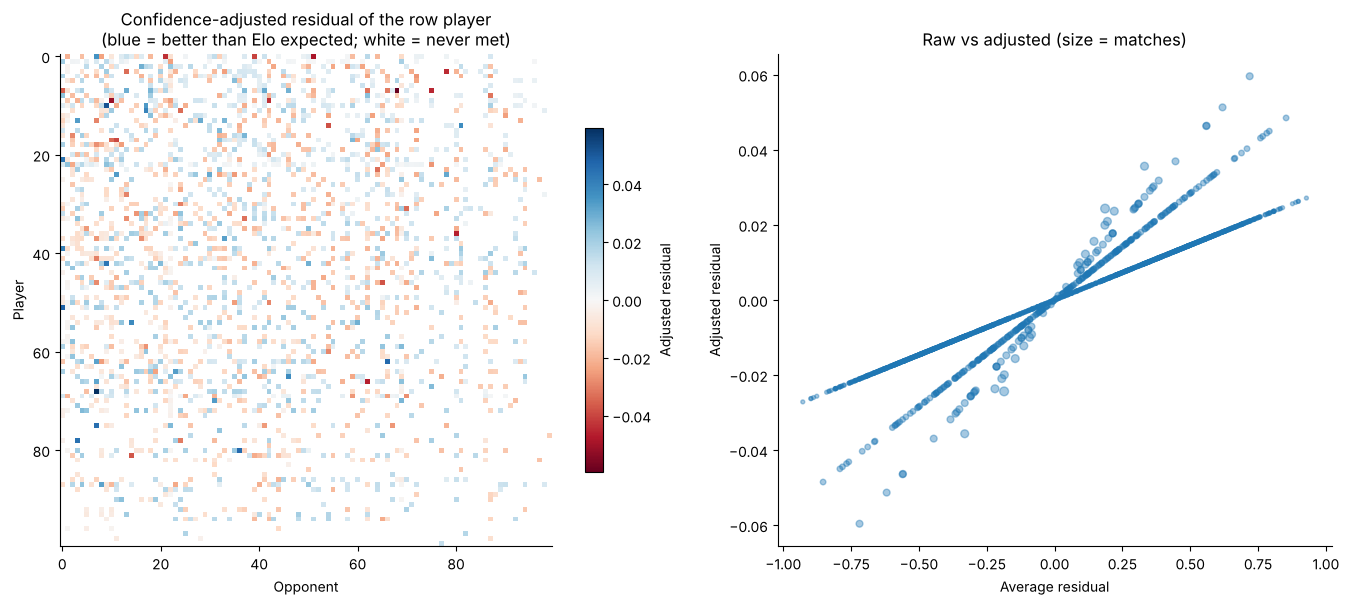

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios": [1.2, 1]})
limit = np.nanmax(np.abs(adjusted))
im = axes[0].imshow(adjusted_matrix, cmap="RdBu", vmin=-limit, vmax=limit,
                    interpolation="nearest")
axes[0].set_title("Confidence-adjusted residual of the row player\n"
                  "(blue = better than Elo expected; white = never met)")
axes[0].set_xlabel("Opponent")
axes[0].set_ylabel("Player")
fig.colorbar(im, ax=axes[0], shrink=0.7, label="Adjusted residual")
axes[1].scatter(cells["mean"], cells["adjusted"], s=cells["n"] * 8,
                alpha=0.4)
axes[1].set_title("Raw vs adjusted (size = matches)")
axes[1].set_xlabel("Average residual")
axes[1].set_ylabel("Adjusted residual")
plt.tight_layout()

## What this means for NMF

**About a fifth of each matrix is filled in**: 1,065 of the 4,950 pairs
(21.5%) met at least once in 2025, most of them only once. Matrix 2 has
slightly fewer (1,029 pairs, 20.6%), because 36 pairs only met in a match
that ended in a retirement. A few players (for example those who missed 2025 through a ban or
injury) have empty rows.

For **matrix 1 (meetings)**, a zero usually just means the draw never put
two players together. Plain NMF treats every zero as a real value, so it
would mostly learn who plays the same tournaments and goes deep in them.

For **matrix 2 (performance against Elo)**, which is the one that says who
plays better than expected against whom, three things need handling before
NMF:

- **Missing values**: ~79% of cells are null, not zero. Use a masked NMF
  that fits only the filled cells (or fill more of the matrix by combining
  several seasons).
- **Negative values**: NMF needs non-negative input, but residuals run from
  -1 to +1. Options are splitting each player's row into a "better than
  expected" part and a "worse than expected" part (two non-negative
  matrices side by side), or shifting the values, e.g. residual + 1.
- **Noise**: most cells come from a single match. Section 5 shrinks each
  cell by how much evidence it rests on; it shows that in one season most
  of the variation is luck, so the adjusted values are small. Combining
  several seasons would give the real patterns more room to show.

The matrix is also antisymmetric (cell A,B = -cell B,A), so each row and its
matching column carry the same information; factorising only the rows (who
a player over- or under-performs against) avoids counting it twice.